# 06. Modelado: fusión temprana vs. stacking

**Objetivo:** predecir `content` y `wording` de cada resumen y comparar dos formas de combinar
dos representaciones del texto:

| Bloque | Qué contiene | Forma |
|---|---|---|
| **A. Features manuales** | Largo, diversidad léxica, traslape de n-gramas con el texto fuente | `(7165, 8)` |
| **B. Embeddings** | Vector semántico del resumen + similitud coseno con el texto fuente | `(7165, 301)` |

* **Opción 1, fusión temprana:** se pegan las columnas de A y B en una sola matriz y se entrena **un** modelo.
* **Opción 2, stacking (fusión tardía):** se entrena un modelo con A, otro con B, y un tercer modelo
  (el "meta-modelo") aprende a combinar sus predicciones.

Para ser honestos con los resultados, las dos opciones se comparan contra:
un `DummyRegressor` (piso), un modelo que solo mira el largo, TF-IDF y cada bloque por separado.

**Validación:** `LeaveOneGroupOut` por `prompt_id` (entrenar con 3 textos fuente y evaluar con el cuarto).
Así se simula la competencia, donde el test traía textos fuente que el modelo nunca vio.

**Métrica:** MCRMSE = promedio del RMSE de `content` y el RMSE de `wording` (menor es mejor).

In [15]:
from pathlib import Path
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "src").is_dir() and (path / "notebooks").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_csv_files
from src.tokenization import tokenize_text
from src.ngrams import prompt_ngram_overlap

INTERIM_DATA_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
for directory in [PROCESSED_DATA_DIR, TABLES_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

datasets = load_csv_files(INTERIM_DATA_DIR, ["summaries_train_clean.csv", "prompts_train_clean.csv"])
summaries: pd.DataFrame = datasets["summaries_train_clean"]
prompts: pd.DataFrame = datasets["prompts_train_clean"]

TARGETS: list[str] = ["content", "wording"]
y: np.ndarray = summaries[TARGETS].to_numpy()          # shape (n, 2): las dos columnas objetivo
groups: np.ndarray = summaries["prompt_id"].to_numpy()  # a qué texto fuente pertenece cada resumen
PROMPT_TITLES: dict[str, str] = prompts.set_index("prompt_id")["prompt_title"].to_dict()

print("Resúmenes:", summaries.shape, "| Prompts:", prompts.shape, "| y:", y.shape)

Resúmenes: (7165, 5) | Prompts: (4, 4) | y: (7165, 2)


### Configuración

`EMBEDDING_BACKEND` decide con qué modelo se calculan los embeddings del bloque B:

* `"spacy"` (por defecto): `en_core_web_md`. Da **vectores de palabras estáticos** (GloVe-like, 300 dimensiones)
  y el vector del documento es el **promedio** de los vectores de sus palabras. No necesita GPU.
  Instalación: `pip install spacy` y luego `python -m spacy download en_core_web_md`.
* `"sentence-transformers"`: `all-MiniLM-L6-v2`. Da un **embedding contextual** de la oración completa
  (384 dimensiones), entrenado justamente para comparar significados de oraciones.
  Instalación: `pip install sentence-transformers` (descarga el modelo de Hugging Face la primera vez).

Los embeddings se guardan en `data/processed/` para no recalcularlos cada vez que se corre el notebook.

In [16]:
EMBEDDING_BACKEND: str = "spacy"      # "spacy" o "sentence-transformers"
RANDOM_STATE: int = 42

# Hiperparámetros de LightGBM fijados de antemano (NO se ajustaron mirando los folds de validación,
# para no hacer trampa). Son valores conservadores para un dataset pequeño.
LGBM_PARAMS: dict = dict(
    n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=30,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.5, random_state=RANDOM_STATE, verbose=-1,
)
# Rango de alphas que RidgeCV prueba internamente (solo con los datos de entrenamiento de cada fold).
RIDGE_ALPHAS: np.ndarray = np.logspace(-2, 4, 13)   # 0.01, 0.03, ..., 10000

## 1. Bloque A: features manuales

Son features **independientes del tema**: contar palabras funciona igual para un texto de Egipto
que para uno de tragedia griega. Por eso esperamos que generalicen bien a prompts nuevos.

| Feature | Qué mide | Por qué podría servir |
|---|---|---|
| `token_count` | Número de palabras | En el EDA tuvo correlación 0.79 con `content` |
| `log_token_count` | Logaritmo del número de palabras | Pasar de 30 a 60 palabras importa más que de 300 a 330 (rendimientos decrecientes) |
| `unique_token_count` | Palabras distintas | Riqueza de vocabulario |
| `lexical_diversity` | Distintas / totales | Cuánto se repite el estudiante |
| `palabras_prompt_overlap` | % de palabras del resumen que están en el texto fuente | Cobertura de ideas (`content`) |
| `bigramas_prompt_overlap` | % de pares de palabras copiados del texto | Copia literal (castiga `wording`) |
| `trigramas_prompt_overlap` | % de tríos de palabras copiados del texto | Copia literal más fuerte |

Se reutilizan `tokenize_text` y `prompt_ngram_overlap` de `src/`, las mismas funciones del EDA.

In [17]:
summary_tokens: pd.Series = summaries["text"].map(tokenize_text)
prompt_tokens: dict[str, list[str]] = (
    prompts.set_index("prompt_id")["prompt_text"].map(tokenize_text).to_dict()
)

features = pd.DataFrame(index=summaries.index)
features["token_count"] = summary_tokens.str.len()
features["log_token_count"] = np.log(features["token_count"])
features["unique_token_count"] = summary_tokens.map(lambda tokens: len(set(tokens)))
features["lexical_diversity"] = features["unique_token_count"] / features["token_count"]
for n, label in [(1, "palabras"), (2, "bigramas"), (3, "trigramas")]:
    features[f"{label}_prompt_overlap"] = [
        prompt_ngram_overlap(tokens, prompt_tokens[prompt_id], n=n)
        for tokens, prompt_id in zip(summary_tokens, summaries["prompt_id"])
    ]

FEATURE_COLUMNS: list[str] = features.columns.tolist()
X_feats: np.ndarray = features.to_numpy()
assert np.isfinite(X_feats).all()
print("Bloque A:", X_feats.shape)
display(features.describe().T.round(3))

Bloque A: (7165, 7)


,count,mean,std,min,25%,50%,75%,max
token_count,7165.0,75.158,53.794,25.000,39.000,58.000,92.000,660.000
log_token_count,7165.0,4.136,0.578,3.219,3.664,4.060,4.522,6.492
unique_token_count,7165.0,48.885,26.300,13.000,30.000,42.000,60.000,280.000
lexical_diversity,7165.0,0.704,0.106,0.259,0.628,0.706,0.782,1.000
palabras_prompt_overlap,7165.0,0.708,0.140,0.282,0.609,0.705,0.806,1.000
bigramas_prompt_overlap,7165.0,0.353,0.233,0.000,0.173,0.290,0.485,1.000
trigramas_prompt_overlap,7165.0,0.228,0.251,0.000,0.038,0.125,0.352,1.000


**Sintaxis que vale la pena recordar:**

* `summaries["text"].map(tokenize_text)` aplica la función a **cada** elemento de la columna y devuelve una
  `Series` de listas. `.str.len()` sobre una Series de listas devuelve el largo de cada lista.
* `lambda tokens: len(set(tokens))` es una **función anónima** de una línea; `set()` elimina repetidos.
* `zip(a, b)` recorre dos secuencias **en paralelo**, como un cierre: toma el elemento 0 de cada una,
  luego el 1, etc. La lista por comprensión `[f(x, y) for x, y in zip(...)]` arma una lista con el resultado.
* `dict[str, list[str]]` es una anotación de tipo: un diccionario con llaves `str` y valores lista de `str`.

## 2. Bloque B: embeddings

Un **embedding** convierte el resumen en un vector denso donde textos con significado parecido quedan cerca.

Además del vector del resumen se calcula una feature extra: la **similitud coseno** entre el embedding del
resumen y el embedding del texto fuente. Mide si el resumen "habla de lo mismo" que el texto original,
sin importar el largo (el coseno compara la **dirección** de los vectores, no su tamaño).

$$\cos(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}$$

In [18]:
def compute_embeddings(texts: list[str], backend: str) -> np.ndarray:
    # Devuelve una matriz (len(texts), dim) con un embedding por texto.
    if backend == "spacy":
        import spacy
        # Solo se necesitan los vectores; se desactivan los componentes que no usamos para que sea más rápido.
        nlp = spacy.load("en_core_web_md", exclude=["tagger", "parser", "ner", "lemmatizer",
                                                     "attribute_ruler", "senter"])
        return np.vstack([doc.vector for doc in nlp.pipe(texts, batch_size=256)])
    if backend == "sentence-transformers":
        from sentence_transformers import SentenceTransformer
        model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
        return model.encode(texts, batch_size=64, show_progress_bar=True)
    raise ValueError(f"Backend desconocido: {backend}")


def cached_embeddings(name: str, texts: list[str], backend: str) -> np.ndarray:
    # Calcula los embeddings una sola vez y los guarda en data/processed/.
    path = PROCESSED_DATA_DIR / f"06_embeddings_{name}_{backend}.npy"
    if path.is_file():
        embeddings = np.load(path)
        if embeddings.shape[0] == len(texts):
            return embeddings
    embeddings = compute_embeddings(texts, backend)
    np.save(path, embeddings)
    return embeddings


start = time.perf_counter()
emb_summaries: np.ndarray = cached_embeddings("summaries", summaries["text"].tolist(), EMBEDDING_BACKEND)
emb_prompts_unique: np.ndarray = cached_embeddings("prompts", prompts["prompt_text"].tolist(), EMBEDDING_BACKEND)
print(f"Embeddings listos en {time.perf_counter() - start:.1f} s")

# Para cada resumen, el embedding de SU texto fuente (misma fila, mismo orden).
prompt_position: dict[str, int] = {pid: i for i, pid in enumerate(prompts["prompt_id"])}
emb_prompt_per_row: np.ndarray = emb_prompts_unique[[prompt_position[pid] for pid in summaries["prompt_id"]]]

cos_sim: np.ndarray = (emb_summaries * emb_prompt_per_row).sum(axis=1) / (
    np.linalg.norm(emb_summaries, axis=1) * np.linalg.norm(emb_prompt_per_row, axis=1) + 1e-9
)
print("emb_summaries:", emb_summaries.shape, "| emb_prompt_per_row:", emb_prompt_per_row.shape,
      "| cos_sim:", cos_sim.shape)
print("Correlación de Spearman cos_sim vs targets:")
display(pd.DataFrame({"cos_sim": cos_sim, "content": y[:, 0], "wording": y[:, 1]})
        .corr(method="spearman").loc[["cos_sim"], TARGETS].round(3))

Embeddings listos en 0.0 s
emb_summaries: (7165, 300) | emb_prompt_per_row: (7165, 300) | cos_sim: (7165,)
Correlación de Spearman cos_sim vs targets:


,content,wording
cos_sim,0.617,0.37


**Sintaxis:**

* `np.vstack([...])` apila una lista de vectores 1D **uno encima de otro** y forma una matriz 2D.
* `emb_prompts_unique[[0, 0, 2, 1, ...]]` es **indexado con una lista** (fancy indexing): devuelve una fila por
  cada índice, en ese orden. Así se "repite" el embedding del prompt para cada resumen que le pertenece.
* `(a * b).sum(axis=1)` multiplica elemento a elemento y suma **por fila** (`axis=1` recorre las columnas):
  es el producto punto de cada par de vectores, para todas las filas a la vez, sin un `for`.
* `np.linalg.norm(a, axis=1)` es el largo (norma) de cada vector fila. El `+ 1e-9` evita dividir entre cero.
* `{pid: i for i, pid in enumerate(...)}` es un **diccionario por comprensión**; `enumerate` devuelve
  pares `(posición, valor)`.

### "Quitar el tema" del embedding

Un embedding de un resumen sobre Egipto se parece a **cualquier** texto sobre Egipto, sea bueno o malo. Si el
modelo aprende "vectores con sabor a Egipto = puntaje X", eso no sirve para un prompt nuevo.
Por eso se prueban dos versiones del bloque B:

* **crudo:** el embedding del resumen tal cual.
* **sin tema:** el embedding del resumen **menos** el embedding de su texto fuente. Lo que queda es en qué
  se **diferencia** el resumen del original, que es más parecido a lo que se califica.

A las dos se les agrega `cos_sim` como columna extra.

In [19]:
X_emb_raw: np.ndarray = np.hstack([emb_summaries, cos_sim[:, None]])
X_emb_notopic: np.ndarray = np.hstack([emb_summaries - emb_prompt_per_row, cos_sim[:, None]])
print("Bloque B crudo:", X_emb_raw.shape, "| Bloque B sin tema:", X_emb_notopic.shape)

Bloque B crudo: (7165, 301) | Bloque B sin tema: (7165, 301)


* `cos_sim[:, None]` convierte un vector de forma `(n,)` en una **columna** de forma `(n, 1)`. `None` agrega un
  eje nuevo (equivale a `np.newaxis`). `np.hstack` necesita que todo sea 2D para pegar por columnas.
* `emb_summaries - emb_prompt_per_row` resta **fila por fila** porque las dos matrices tienen la misma forma.

## 3. Esquema de validación y métrica

`LeaveOneGroupOut` genera 4 folds: en cada uno, los resúmenes de **un** prompt quedan como validación y
los de los otros 3 como entrenamiento. Todo lo que "aprende" de los datos (escaladores, PCA, el alpha de
RidgeCV, el vocabulario de TF-IDF) se ajusta **dentro** de cada fold con el `Pipeline`, para evitar fuga de datos.

Se guardan las predicciones **out-of-fold** (OOF): la predicción de cada resumen la hizo un modelo que
nunca lo vio. Con ellas se calcula el RMSE global de cada target y el MCRMSE.

In [20]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import root_mean_squared_error

logo = LeaveOneGroupOut()


def mcrmse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    # Promedio del RMSE de cada columna objetivo.
    return float(np.mean([root_mean_squared_error(y_true[:, j], y_pred[:, j])
                          for j in range(y_true.shape[1])]))


def take_rows(X, idx: np.ndarray):
    # Selecciona filas tanto de un ndarray como de un DataFrame o Series.
    return X.iloc[idx] if isinstance(X, (pd.DataFrame, pd.Series)) else X[idx]


results: list[dict] = []        # una fila por modelo (resultado global)
fold_results: list[dict] = []   # una fila por modelo y por prompt de validación
oof_predictions: dict[str, np.ndarray] = {}


def register(name: str, family: str, oof: np.ndarray, seconds: float) -> None:
    # Guarda métricas globales y por fold de un modelo ya evaluado.
    oof_predictions[name] = oof
    results.append({
        "modelo": name, "familia": family,
        "rmse_content": root_mean_squared_error(y[:, 0], oof[:, 0]),
        "rmse_wording": root_mean_squared_error(y[:, 1], oof[:, 1]),
        "mcrmse": mcrmse(y, oof),
        "segundos": seconds,
    })
    for prompt_id in np.unique(groups):
        mask = groups == prompt_id
        fold_results.append({
            "modelo": name, "prompt_validacion": PROMPT_TITLES[prompt_id],
            "rmse_content": root_mean_squared_error(y[mask, 0], oof[mask, 0]),
            "rmse_wording": root_mean_squared_error(y[mask, 1], oof[mask, 1]),
            "mcrmse": mcrmse(y[mask], oof[mask]),
        })
    print(f"{name:<38} content={results[-1]['rmse_content']:.4f}  "
          f"wording={results[-1]['rmse_wording']:.4f}  MCRMSE={results[-1]['mcrmse']:.4f}  ({seconds:.1f} s)")


def evaluate(name: str, family: str, make_model, X) -> np.ndarray:
    # Entrena con LeaveOneGroupOut y devuelve las predicciones out-of-fold.
    oof = np.zeros_like(y, dtype=float)
    start = time.perf_counter()
    for train_idx, valid_idx in logo.split(X, y, groups):
        model = make_model()                                   # modelo nuevo en cada fold
        model.fit(take_rows(X, train_idx), y[train_idx])
        oof[valid_idx] = model.predict(take_rows(X, valid_idx))
    register(name, family, oof, time.perf_counter() - start)
    return oof

**Sintaxis:**

* `logo.split(X, y, groups)` es un **generador**: en cada vuelta del `for` entrega una tupla
  `(train_idx, valid_idx)` con los índices de las filas. El desempaquetado `for a, b in ...` los separa.
* `make_model` es una **función que crea un modelo** (una "fábrica"). Se pasa así, en vez del modelo ya creado,
  para garantizar que cada fold empieza con un modelo **nuevo, sin entrenar**. Se usa con `lambda: Ridge()`.
* `np.zeros_like(y, dtype=float)` crea una matriz de ceros con la misma forma que `y`.
* `oof[valid_idx] = ...` escribe las predicciones solo en las filas de validación de ese fold; al terminar
  los 4 folds, todas las filas quedan llenas exactamente una vez.
* `isinstance(X, (pd.DataFrame, pd.Series))` revisa si `X` es de alguno de esos tipos (acepta una tupla).
* `time.perf_counter()` es un cronómetro de alta precisión; la resta de dos lecturas da segundos transcurridos.

## 4. Baselines

| Modelo | Qué responde |
|---|---|
| `DummyRegressor` | ¿Cuánto se equivoca alguien que siempre dice "el promedio"? (el piso) |
| Solo largo + Ridge | ¿Cuánto se explica con **contar palabras**? |
| TF-IDF + Ridge | ¿Sirve memorizar vocabulario cuando el prompt de validación es nuevo? |

In [21]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, Ridge
from sklearn.feature_extraction.text import TfidfVectorizer

evaluate("Dummy (media)", "Baseline", lambda: DummyRegressor(strategy="mean"), X_feats)

evaluate("Solo largo + Ridge", "Baseline",
         lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=RIDGE_ALPHAS, alpha_per_target=True)),
         features[["token_count", "log_token_count"]].to_numpy())

evaluate("TF-IDF (1-2 gramas) + Ridge", "Baseline",
         lambda: make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True),
                               RidgeCV(alphas=RIDGE_ALPHAS, alpha_per_target=True)),
         summaries["text"]);

Dummy (media)                          content=1.0463  wording=1.0535  MCRMSE=1.0499  (0.0 s)
Solo largo + Ridge                     content=0.5607  wording=0.8624  MCRMSE=0.7116  (0.0 s)
TF-IDF (1-2 gramas) + Ridge            content=0.9579  wording=0.9659  MCRMSE=0.9619  (87.0 s)


* `make_pipeline(paso1, paso2)` encadena pasos y les pone nombre automático. Al hacer `.fit()`, el escalador
  aprende media y desviación **solo con el train del fold**, y luego le pasa los datos ya escalados a Ridge.
* `RidgeCV(alphas=..., alpha_per_target=True)` prueba varios alphas (la fuerza del "freno" de regularización)
  usando validación interna **solo dentro del train**, y elige uno distinto para `content` y para `wording`.
* `TfidfVectorizer(min_df=3, sublinear_tf=True)`: ignora palabras que aparecen en menos de 3 resúmenes y usa
  `1 + log(frecuencia)` en vez de la frecuencia cruda, para que repetir una palabra 10 veces no pese 10 veces más.
* El `;` al final de la última línea evita que Jupyter imprima el arreglo devuelto.

## 5. Cada bloque por separado

Antes de combinar hay que saber cuánto aporta cada bloque solo. Si la combinación no supera al mejor
bloque individual, combinar no sirvió.

In [22]:
from sklearn.multioutput import MultiOutputRegressor
from sklearn.decomposition import PCA
from lightgbm import LGBMRegressor


def make_ridge() -> Pipeline:
    return make_pipeline(StandardScaler(), RidgeCV(alphas=RIDGE_ALPHAS, alpha_per_target=True))


def make_lgbm() -> MultiOutputRegressor:
    # LightGBM predice un solo número; MultiOutputRegressor entrena uno por target.
    return MultiOutputRegressor(LGBMRegressor(**LGBM_PARAMS))


evaluate("A. Features + Ridge", "Bloque A", make_ridge, X_feats)
evaluate("A. Features + LightGBM", "Bloque A", make_lgbm, X_feats)
def make_emb_ridge() -> Pipeline:
    # Embedding: escalar + comprimir a 16 componentes con PCA + Ridge
    return make_pipeline(StandardScaler(), PCA(n_components=16, random_state=RANDOM_STATE),
                         RidgeCV(alphas=RIDGE_ALPHAS, alpha_per_target=True))


evaluate("B. Embedding crudo + Ridge", "Bloque B", make_ridge, X_emb_raw)
evaluate("B. Embedding sin tema + Ridge", "Bloque B", make_ridge, X_emb_notopic)
evaluate("B. Embedding sin tema + PCA(16) + Ridge", "Bloque B", make_emb_ridge, X_emb_notopic);

A. Features + Ridge                    content=0.5097  wording=0.7133  MCRMSE=0.6115  (0.1 s)
A. Features + LightGBM                 content=0.4853  wording=0.6771  MCRMSE=0.5812  (0.9 s)
B. Embedding crudo + Ridge             content=1.0519  wording=1.2847  MCRMSE=1.1683  (1.2 s)
B. Embedding sin tema + Ridge          content=1.0538  wording=1.2439  MCRMSE=1.1489  (1.2 s)
B. Embedding sin tema + PCA(16) + Ridge content=1.0456  wording=1.0622  MCRMSE=1.0539  (0.3 s)


* `LGBMRegressor(**LGBM_PARAMS)`: el `**` **desempaqueta un diccionario** como argumentos con nombre.
  Es lo mismo que escribir `LGBMRegressor(n_estimators=300, learning_rate=0.03, ...)`.
* `def make_ridge() -> Pipeline:` la anotación `-> Pipeline` documenta qué tipo devuelve la función.

**Ojo con el bloque B:** `RidgeCV` elige su alpha con validación interna *leave-one-out* que **no** respeta los
prompts (mezcla resúmenes de los 3 prompts de entrenamiento). Para esa validación interna, memorizar el "sabor"
de cada tema parece buena idea, así que elige un alpha bajo; luego, en el prompt nuevo, ese conocimiento no sirve.
Es el mismo problema de la validación que se discutió al inicio, pero escondido dentro del modelo.

## 6. Opción 1: fusión temprana

```
[ A: 7 features | B: 300 embedding + cos_sim ]  →  una sola matriz  →  un modelo  →  [content, wording]
```

Dos versiones:

* **Ridge:** con `ColumnTransformer` cada bloque recibe su propio preprocesamiento. Las features se estandarizan;
  el embedding se estandariza y se comprime con **PCA** a 16 componentes. Sin el PCA, las ~300 columnas del
  embedding "ahogan" a las 7 features (Ridge reparte el peso entre todas las columnas).
* **LightGBM:** recibe todas las columnas tal cual (los árboles no necesitan escalado) y elige solo en qué
  columnas cortar.

Se usa el embedding **sin tema**, que en la sección 5 fue ligeramente mejor en promedio (aunque no en todos los prompts).

Se agrega una tercera versión, **fusión mínima**: las features más **solo la columna** `cos_sim` del bloque B.
Sirve para responder: ¿la información útil del embedding está en sus 300 dimensiones o casi toda en la similitud con el texto fuente?

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

X_fusion: np.ndarray = np.hstack([X_feats, X_emb_notopic])
idx_feats: list[int] = list(range(X_feats.shape[1]))
idx_emb: list[int] = list(range(X_feats.shape[1], X_fusion.shape[1]))
print("Matriz de fusión:", X_fusion.shape, "| columnas A:", len(idx_feats), "| columnas B:", len(idx_emb))


def make_fusion_ridge() -> Pipeline:
    preprocessor = ColumnTransformer([
        ("features", StandardScaler(), idx_feats),
        ("embedding", make_pipeline(StandardScaler(), PCA(n_components=16, random_state=RANDOM_STATE)), idx_emb),
    ])
    return Pipeline([
        ("prep", preprocessor),
        ("ridge", RidgeCV(alphas=RIDGE_ALPHAS, alpha_per_target=True)),
    ])


evaluate("Opción 1: Fusión temprana + Ridge", "Opción 1", make_fusion_ridge, X_fusion)
evaluate("Opción 1: Fusión temprana + LightGBM", "Opción 1", make_lgbm, X_fusion)

X_feats_cos: np.ndarray = np.hstack([X_feats, cos_sim[:, None]])   # (n, 8)
evaluate("Opción 1: Fusión mínima (A + cos_sim) + LightGBM", "Opción 1", make_lgbm, X_feats_cos);

Matriz de fusión: (7165, 308) | columnas A: 7 | columnas B: 301
Opción 1: Fusión temprana + Ridge      content=0.5036  wording=0.7102  MCRMSE=0.6069  (0.5 s)
Opción 1: Fusión temprana + LightGBM   content=0.4869  wording=0.6682  MCRMSE=0.5776  (8.2 s)
Opción 1: Fusión mínima (A + cos_sim) + LightGBM content=0.4800  wording=0.6713  MCRMSE=0.5756  (1.2 s)


* `ColumnTransformer([(nombre, transformador, columnas), ...])` aplica un transformador distinto a cada grupo de
  columnas (se indican por posición) y al final **vuelve a pegar** los resultados lado a lado. La salida tiene
  7 + 16 = 23 columnas.
* `Pipeline([("prep", ...), ("ridge", ...)])` es igual que `make_pipeline`, pero con nombres elegidos por ti.
  Los nombres sirven para acceder a cada paso después, por ejemplo `modelo.named_steps["ridge"].alpha_`.
* `list(range(7, 308))` genera la lista de posiciones 7, 8, ..., 307 (el `range` excluye el final).

## 7. Opción 2: stacking (fusión tardía)

```
Modelo A (LightGBM, solo features)   → pred_A (n, 2) ─┐
                                                       ├─→ meta-modelo Ridge → [content, wording]
Modelo B (PCA + Ridge, embedding)    → pred_B (n, 2) ─┘
```

El meta-modelo recibe 4 columnas (`content_A`, `wording_A`, `content_B`, `wording_B`) y aprende **cuánto confiar
en cada modelo base**.

**La trampa a evitar:** si el meta-modelo se entrena con predicciones que los modelos base hicieron sobre datos
que **ya habían visto**, aprende a confiar ciegamente en ellos (porque en train se ven perfectos). Por eso se
usa **validación anidada**:

1. **Fold externo** (4 vueltas): se aparta un prompt para evaluar.
2. **Folds internos** (3 vueltas, solo con los 3 prompts de train): se generan predicciones out-of-fold de A y B.
   Con esas predicciones "honestas" se entrena el meta-modelo.
3. A y B se reentrenan con los 3 prompts completos y predicen el prompt apartado; el meta-modelo combina esas
   predicciones.

Así, el prompt de evaluación nunca participa en ningún entrenamiento, ni de los modelos base ni del meta-modelo.

In [24]:
def evaluate_stacking(name: str, X_a: np.ndarray, make_a, X_b: np.ndarray, make_b) -> np.ndarray:
    oof = np.zeros_like(y, dtype=float)
    meta_weights: list[pd.DataFrame] = []
    start = time.perf_counter()

    for train_idx, valid_idx in logo.split(X_a, y, groups):
        # (2) Predicciones out-of-fold DENTRO del train para entrenar al meta-modelo
        inner_preds = np.zeros((len(train_idx), 4))
        for inner_train, inner_valid in logo.split(train_idx, groups=groups[train_idx]):
            rows_fit, rows_pred = train_idx[inner_train], train_idx[inner_valid]
            model_a = make_a().fit(X_a[rows_fit], y[rows_fit])
            model_b = make_b().fit(X_b[rows_fit], y[rows_fit])
            inner_preds[inner_valid] = np.hstack([model_a.predict(X_a[rows_pred]),
                                                  model_b.predict(X_b[rows_pred])])
        meta = Ridge(alpha=1.0).fit(inner_preds, y[train_idx])

        # (3) Modelos base con todo el train externo -> predicción del prompt apartado
        model_a = make_a().fit(X_a[train_idx], y[train_idx])
        model_b = make_b().fit(X_b[train_idx], y[train_idx])
        outer_preds = np.hstack([model_a.predict(X_a[valid_idx]), model_b.predict(X_b[valid_idx])])
        oof[valid_idx] = meta.predict(outer_preds)

        meta_weights.append(pd.DataFrame(
            meta.coef_, index=[f"meta_{t}" for t in TARGETS],
            columns=["content_A", "wording_A", "content_B", "wording_B"],
        ).assign(prompt_validacion=PROMPT_TITLES[groups[valid_idx][0]]))

    register(name, "Opción 2", oof, time.perf_counter() - start)
    return pd.concat(meta_weights)


stack_weights = evaluate_stacking("Opción 2: Stacking (LightGBM A + Ridge B)",
                                  X_feats, make_lgbm, X_emb_notopic, make_emb_ridge)
print("\nPesos del meta-modelo (promedio de los 4 folds externos):")
display(stack_weights.groupby(level=0).mean(numeric_only=True).round(3))

Opción 2: Stacking (LightGBM A + Ridge B) content=0.5054  wording=0.7011  MCRMSE=0.6032  (5.5 s)

Pesos del meta-modelo (promedio de los 4 folds externos):


,content_A,wording_A,content_B,wording_B
meta_content,0.902,0.068,0.254,-0.338
meta_wording,0.137,0.786,0.137,-0.347


**Sintaxis:**

* `logo.split(train_idx, groups=groups[train_idx])`: los índices **internos** que devuelve son posiciones
  **dentro de** `train_idx`. Por eso se traducen con `train_idx[inner_train]` a posiciones reales del dataset.
  Este detalle es la fuente de bugs más común al hacer validación anidada.
* `make_a().fit(...)` encadena: crea el modelo y lo entrena en la misma línea (`.fit()` devuelve el propio modelo).
* `meta.coef_` tiene forma `(2, 4)`: una fila por target y una columna por cada predicción base. Un peso cercano a
  1 en `content_A` para la fila `meta_content` significa "para predecir content, confía casi todo en el modelo A".
* `.assign(columna=valor)` agrega una columna y devuelve un DataFrame nuevo (no modifica el original).
* `groupby(level=0)` agrupa por el **índice** (aquí `meta_content` / `meta_wording`) en vez de por una columna.

## 8. Comparación final

In [25]:
results_df = (pd.DataFrame(results)
              .sort_values("mcrmse")
              .reset_index(drop=True))
dummy_mcrmse = results_df.loc[results_df["modelo"] == "Dummy (media)", "mcrmse"].item()
results_df["mejora_vs_dummy_%"] = 100 * (1 - results_df["mcrmse"] / dummy_mcrmse)

fold_df = pd.DataFrame(fold_results)
fold_std = fold_df.groupby("modelo")["mcrmse"].std().rename("mcrmse_std_entre_prompts")
results_df = results_df.merge(fold_std, on="modelo")

display(results_df.round(4))
results_df.to_csv(TABLES_DIR / "06_model_comparison.csv", index=False)
fold_df.to_csv(TABLES_DIR / "06_model_comparison_by_prompt.csv", index=False)
stack_weights.to_csv(TABLES_DIR / "06_stacking_meta_weights.csv", index_label="target")

print("\nMCRMSE por prompt de validación:")
display(fold_df.pivot(index="modelo", columns="prompt_validacion", values="mcrmse")
        .loc[results_df["modelo"]].round(3))

,modelo,familia,rmse_content,rmse_wording,mcrmse,segundos,mejora_vs_dummy_%,mcrmse_std_entre_prompts
0,Opción 1: Fusión mínima (A + cos_sim) + LightGBM,Opción 1,0.4800,0.6713,0.5756,1.1642,45.1746,0.0782
1,Opción 1: Fusión temprana + LightGBM,Opción 1,0.4869,0.6682,0.5776,8.1537,44.9906,0.0938
2,A. Features + LightGBM,Bloque A,0.4853,0.6771,0.5812,0.8515,44.6439,0.0853
3,Opción 2: Stacking (LightGBM A + Ridge B),Opción 2,0.5054,0.7011,0.6032,5.4885,42.5446,0.0800
4,Opción 1: Fusión temprana + Ridge,Opción 1,0.5036,0.7102,0.6069,0.4588,42.1943,0.0760
5,A. Features + Ridge,Bloque A,0.5097,0.7133,0.6115,0.0614,41.7619,0.0824
6,Solo largo + Ridge,Baseline,0.5607,0.8624,0.7116,0.0351,32.2271,0.0868
7,TF-IDF (1-2 gramas) + Ridge,Baseline,0.9579,0.9659,0.9619,86.9775,8.3831,0.0678
8,Dummy (media),Baseline,1.0463,1.0535,1.0499,0.0065,0.0000,0.1057
9,B. Embedding sin tema + PCA(16) + Ridge,Bloque B,1.0456,1.0622,1.0539,0.2813,-0.3824,0.0863



MCRMSE por prompt de validación:


prompt_validacion,Egyptian Social Structure,Excerpt from The Jungle,On Tragedy,The Third Wave
modelo,,,,
Opción 1: Fusión mínima (A + cos_sim) + LightGBM,0.625,0.512,0.522,0.672
Opción 1: Fusión temprana + LightGBM,0.603,0.502,0.535,0.714
A. Features + LightGBM,0.641,0.504,0.528,0.680
Opción 2: Stacking (LightGBM A + Ridge B),0.654,0.515,0.576,0.694
Opción 1: Fusión temprana + Ridge,0.650,0.551,0.553,0.705
A. Features + Ridge,0.657,0.563,0.542,0.719
Solo largo + Ridge,0.687,0.736,0.632,0.836
TF-IDF (1-2 gramas) + Ridge,0.959,0.878,0.985,1.041
Dummy (media),1.031,0.991,1.019,1.222


* `.item()` extrae el único valor de una Series de un elemento como número de Python (falla si hay 0 o más de 1,
  lo cual también sirve como verificación).
* `.pivot(index=..., columns=..., values=...)` reorganiza una tabla "larga" (una fila por modelo y prompt) en una
  tabla "ancha" (modelos en filas, prompts en columnas). `.loc[orden]` reordena las filas como la tabla principal.
* La desviación estándar entre prompts mezcla dos cosas: qué tan difícil es cada prompt y qué tan estable es el modelo.
  Para comparar dos modelos de forma justa conviene una comparación **pareada**: restar sus MCRMSE **en el mismo prompt**.

In [26]:
# Comparación pareada contra el mejor bloque individual: diferencia de MCRMSE en cada prompt
# (negativo = el modelo es mejor que la referencia en ese prompt)
REFERENCE: str = "A. Features + LightGBM"
by_prompt = fold_df.pivot(index="modelo", columns="prompt_validacion", values="mcrmse")
compared = ["Opción 1: Fusión mínima (A + cos_sim) + LightGBM", "Opción 1: Fusión temprana + LightGBM",
            "Opción 2: Stacking (LightGBM A + Ridge B)"]
paired = by_prompt.loc[compared].sub(by_prompt.loc[REFERENCE], axis=1)
paired["prompts_donde_gana"] = (paired < 0).sum(axis=1)
paired["diferencia_promedio"] = paired.drop(columns="prompts_donde_gana").mean(axis=1)
display(paired.round(3))
paired.to_csv(TABLES_DIR / "06_paired_vs_features_lgbm.csv", index_label="modelo")

prompt_validacion,Egyptian Social Structure,Excerpt from The Jungle,On Tragedy,The Third Wave,prompts_donde_gana,diferencia_promedio
modelo,,,,,,
Opción 1: Fusión mínima (A + cos_sim) + LightGBM,-0.015,0.008,-0.006,-0.008,3,-0.005
Opción 1: Fusión temprana + LightGBM,-0.038,-0.002,0.007,0.034,2,0.000
Opción 2: Stacking (LightGBM A + Ridge B),0.013,0.011,0.048,0.015,0,0.022


* `.sub(serie, axis=1)` resta una Series a **cada fila** del DataFrame, alineando por nombre de columna
  (aquí, por prompt). Es la resta pareada.
* `(paired < 0)` produce un DataFrame de `True/False`; `.sum(axis=1)` cuenta los `True` por fila
  (en Python, `True` vale 1 al sumar).

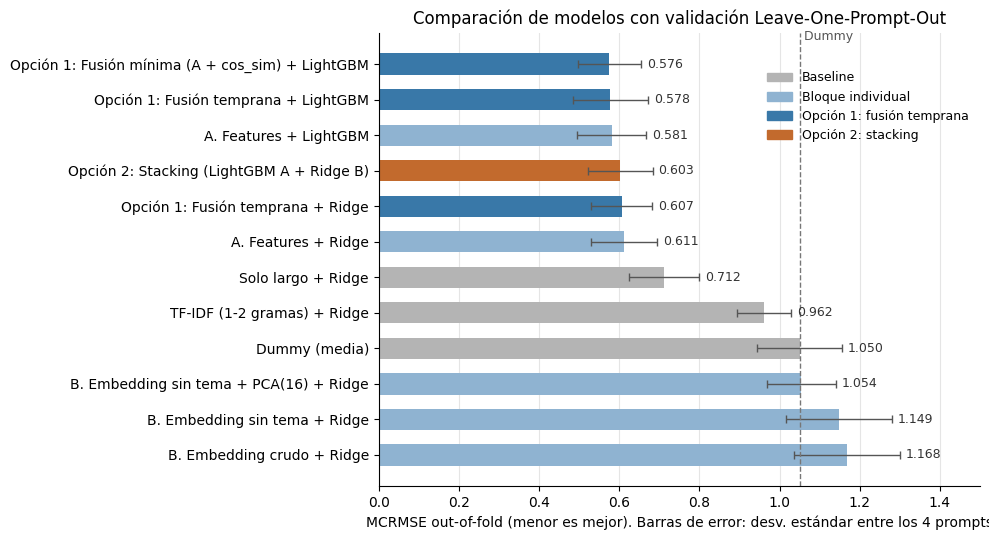

In [27]:
FAMILY_COLORS: dict[str, str] = {
    "Baseline": "#b4b4b4", "Bloque A": "#8fb3d1", "Bloque B": "#8fb3d1",
    "Opción 1": "#3978a8", "Opción 2": "#c26a2d",
}
plot_df = results_df.sort_values("mcrmse", ascending=False)

fig, ax = plt.subplots(figsize=[10, 5.5])
ax.barh(plot_df["modelo"], plot_df["mcrmse"], height=0.6,
        color=plot_df["familia"].map(FAMILY_COLORS),
        xerr=plot_df["mcrmse_std_entre_prompts"], error_kw={"ecolor": "#555555", "capsize": 3, "lw": 1})
for row_position, (value, spread) in enumerate(zip(plot_df["mcrmse"], plot_df["mcrmse_std_entre_prompts"])):
    ax.text(value + spread + 0.015, row_position, f"{value:.3f}", va="center", fontsize=9, color="#333333")
ax.axvline(dummy_mcrmse, color="#777777", linestyle="--", linewidth=1)
ax.text(dummy_mcrmse, len(plot_df) - 0.4, " Dummy", color="#555555", fontsize=9, va="bottom")
ax.set(xlabel="MCRMSE out-of-fold (menor es mejor). Barras de error: desv. estándar entre los 4 prompts",
       title="Comparación de modelos con validación Leave-One-Prompt-Out")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in
           [FAMILY_COLORS["Baseline"], FAMILY_COLORS["Bloque A"], FAMILY_COLORS["Opción 1"], FAMILY_COLORS["Opción 2"]]]
ax.legend(handles, ["Baseline", "Bloque individual", "Opción 1: fusión temprana", "Opción 2: stacking"],
          loc="upper right", bbox_to_anchor=(1.0, 0.94), frameon=False, fontsize=9)
ax.set_xlim(0, 1.5)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

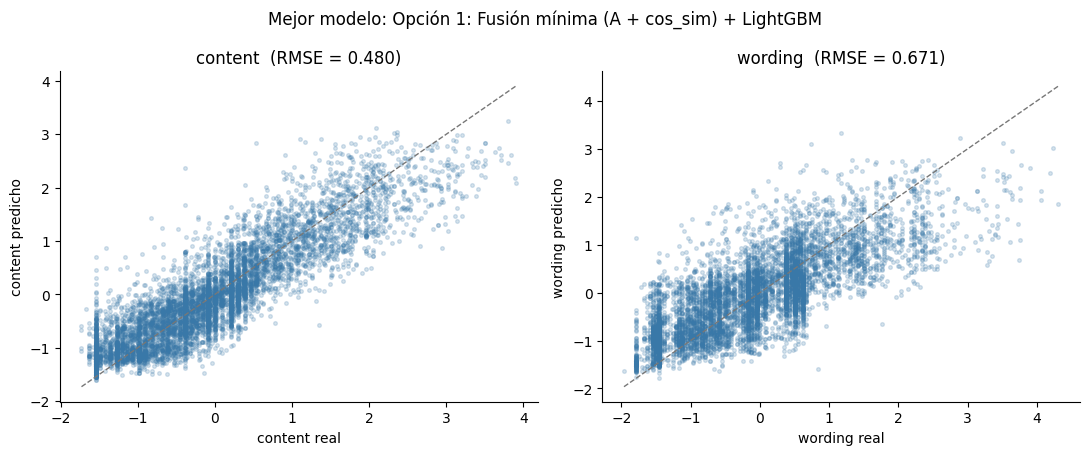

In [28]:
# Predicho vs. real del mejor modelo (cuanto más pegados a la diagonal, mejor)
best_name: str = results_df.loc[0, "modelo"]
best_oof: np.ndarray = oof_predictions[best_name]

fig, axes = plt.subplots(1, 2, figsize=[11, 4.6])
for j, (ax, target) in enumerate(zip(axes, TARGETS)):
    ax.scatter(y[:, j], best_oof[:, j], s=7, alpha=0.2, color="#3978a8")
    limits = [min(y[:, j].min(), best_oof[:, j].min()), max(y[:, j].max(), best_oof[:, j].max())]
    ax.plot(limits, limits, color="#777777", linestyle="--", linewidth=1)
    rmse_value = root_mean_squared_error(y[:, j], best_oof[:, j])
    ax.set(xlabel=f"{target} real", ylabel=f"{target} predicho", title=f"{target}  (RMSE = {rmse_value:.3f})")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Mejor modelo: {best_name}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_best_model_pred_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Comparación de embeddings: spaCy vs. Sentence-BERT

Hasta aquí el bloque B usó **spaCy** (`en_core_web_md`): el vector de un resumen es el **promedio** de los vectores de sus
palabras. En la sección 2 vimos un problema: con promedios, los textos largos se parecen más al texto fuente solo por
tener más palabras, así que `cos_sim` termina midiendo en buena parte el **largo**.

**Sentence-BERT** (`all-MiniLM-L6-v2`, Reimers y Gurevych, 2019) es un transformer entrenado específicamente para que
oraciones con significado parecido tengan vectores parecidos. Aquí se usa **congelado** (sin fine-tuning): solo cambia el
instrumento que genera los embeddings; el resto del pipeline es idéntico.

Para cada backend se mide:

* **Diagnóstico de `cos_sim`:** correlación con los targets y con el largo, y la **correlación parcial** con los targets
  controlando el largo (a igual largo, ¿sigue habiendo relación?). Se calcula dentro de cada prompt y se promedia.
* **Tres modelos** con la misma validación Leave-One-Prompt-Out: el embedding solo (sin tema + PCA + Ridge), la fusión
  mínima (features + `cos_sim`) y la fusión completa (features + embedding completo), ambas con LightGBM.

**Requisitos para Sentence-BERT:** `pip install sentence-transformers` y acceso a internet la primera vez (descarga el
modelo de Hugging Face, unos 90 MB). Si no está disponible, la celda lo indica y compara solo spaCy. Los embeddings se
guardan en `data/processed/`, así que las siguientes ejecuciones no vuelven a calcularlos.

In [29]:
from scipy.stats import rankdata

EMBEDDING_BACKENDS: list[str] = ["spacy", "sentence-transformers"]
log_length: np.ndarray = np.log(features["token_count"].to_numpy())


def partial_spearman(x: np.ndarray, y_: np.ndarray, z: np.ndarray, grp: np.ndarray) -> float:
    # Correlación de Spearman entre x e y_ quitando el efecto de z (dentro de cada prompt, luego promedio).
    values: list[float] = []
    for g in np.unique(grp):
        m = grp == g
        rx, ry, rz = rankdata(x[m]), rankdata(y_[m]), rankdata(z[m])
        residual = lambda a: a - np.polyval(np.polyfit(rz, a, 1), rz)
        values.append(np.corrcoef(residual(rx), residual(ry))[0, 1])
    return float(np.mean(values))


def spearman_within(x: np.ndarray, y_: np.ndarray, grp: np.ndarray) -> float:
    # Correlación de Spearman calculada dentro de cada prompt y promediada.
    return float(np.mean([pd.Series(x[grp == g]).corr(pd.Series(y_[grp == g]), method="spearman")
                          for g in np.unique(grp)]))


backend_rows: list[dict] = []
for backend in EMBEDDING_BACKENDS:
    try:
        emb_s = cached_embeddings("summaries", summaries["text"].tolist(), backend)
        emb_p = cached_embeddings("prompts", prompts["prompt_text"].tolist(), backend)
    except Exception as err:   # librería no instalada o sin acceso a Hugging Face
        print(f"[{backend}] no disponible en este entorno ({type(err).__name__}). Se omite.")
        continue

    emb_p_row = emb_p[[prompt_position[pid] for pid in summaries["prompt_id"]]]
    cos_b = (emb_s * emb_p_row).sum(axis=1) / (
        np.linalg.norm(emb_s, axis=1) * np.linalg.norm(emb_p_row, axis=1) + 1e-9)
    X_notopic_b = np.hstack([emb_s - emb_p_row, cos_b[:, None]])

    print(f"\n[{backend}] embeddings: {emb_s.shape}")
    r_b = evaluate(f"[{backend}] B. Embedding sin tema + PCA(16) + Ridge", "Comparación embeddings",
                   make_emb_ridge, X_notopic_b)
    r_min = evaluate(f"[{backend}] Fusión mínima (A + cos_sim) + LightGBM", "Comparación embeddings",
                     make_lgbm, np.hstack([X_feats, cos_b[:, None]]))
    r_full = evaluate(f"[{backend}] Fusión completa + LightGBM", "Comparación embeddings",
                      make_lgbm, np.hstack([X_feats, X_notopic_b]))

    backend_rows.append({
        "backend": backend,
        "dimensiones": emb_s.shape[1],
        "cos_sim_vs_content": spearman_within(cos_b, y[:, 0], groups),
        "cos_sim_vs_wording": spearman_within(cos_b, y[:, 1], groups),
        "cos_sim_vs_largo": spearman_within(cos_b, log_length, groups),
        "parcial_content_dado_largo": partial_spearman(cos_b, y[:, 0], log_length, groups),
        "parcial_wording_dado_largo": partial_spearman(cos_b, y[:, 1], log_length, groups),
        "mcrmse_embedding_solo": mcrmse(y, r_b),
        "mcrmse_fusion_minima": mcrmse(y, r_min),
        "mcrmse_fusion_completa": mcrmse(y, r_full),
    })

backend_df = pd.DataFrame(backend_rows).set_index("backend")
print("\nReferencia sin embeddings, A. Features + LightGBM: MCRMSE =",
      round(mcrmse(y, oof_predictions["A. Features + LightGBM"]), 4))
display(backend_df.round(3))
backend_df.to_csv(TABLES_DIR / "06_embedding_backend_comparison.csv")


[spacy] embeddings: (7165, 300)
[spacy] B. Embedding sin tema + PCA(16) + Ridge content=1.0456  wording=1.0622  MCRMSE=1.0539  (0.3 s)
[spacy] Fusión mínima (A + cos_sim) + LightGBM content=0.4800  wording=0.6713  MCRMSE=0.5756  (1.6 s)
[spacy] Fusión completa + LightGBM     content=0.4869  wording=0.6682  MCRMSE=0.5776  (11.6 s)
[sentence-transformers] no disponible en este entorno (ModuleNotFoundError). Se omite.

Referencia sin embeddings, A. Features + LightGBM: MCRMSE = 0.5812


,dimensiones,cos_sim_vs_content,cos_sim_vs_wording,cos_sim_vs_largo,parcial_content_dado_largo,parcial_wording_dado_largo,mcrmse_embedding_solo,mcrmse_fusion_minima,mcrmse_fusion_completa
backend,,,,,,,,,
spacy,300,0.649,0.428,0.735,0.048,-0.067,1.054,0.576,0.578


**Sintaxis:**

* `try: ... except Exception as err:` atrapa cualquier error al cargar el backend (librería no instalada, sin internet)
  y permite seguir con los demás en vez de detener el notebook. `type(err).__name__` da el nombre del tipo de error.
* `rankdata` (de SciPy) convierte valores en rangos (1 = el menor). La correlación de Spearman es la correlación de
  Pearson entre rangos.
* La **correlación parcial** se calcula quitando a cada variable la parte que explica el largo (con una regresión
  lineal sobre los rangos, `np.polyfit(..., 1)`) y correlacionando lo que sobra (los residuos).
* `residual = lambda a: ...` define una función pequeña en una línea. Usa `rz` de la vuelta actual del `for`.

**Cómo leer la tabla:**

* Si `parcial_content_dado_largo` de Sentence-BERT es claramente mayor que el de spaCy (que ronda 0.05), el embedding
  contextual sí mide **cobertura de ideas** y no solo largo.
* Si además `mcrmse_fusion_minima` de Sentence-BERT es menor que la de spaCy y que la referencia sin embeddings, conviene
  adoptar Sentence-BERT en el modelo final. Para afirmarlo, revisar también la tabla por prompt
  (`06_model_comparison_by_prompt.csv`): la mejora debería repetirse en la mayoría de los cuatro prompts.
* Si la tabla solo muestra spaCy, es porque Sentence-BERT no estaba disponible en el entorno donde se ejecutó.

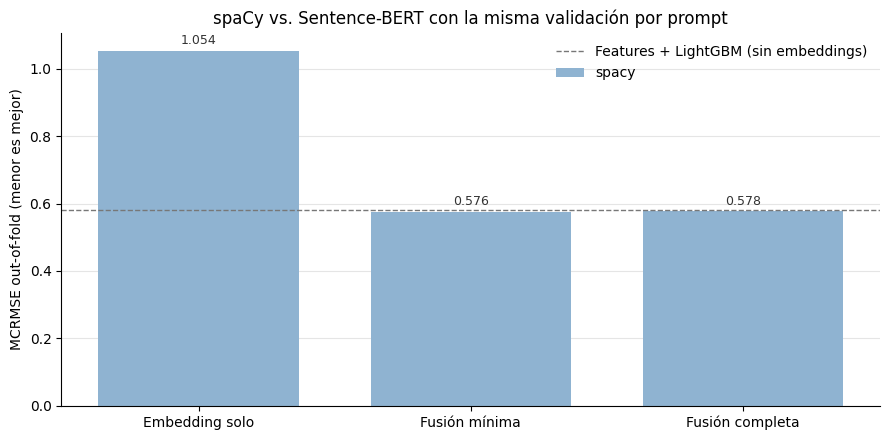

In [30]:
if len(backend_df) > 0:
    model_cols = {"mcrmse_embedding_solo": "Embedding solo", "mcrmse_fusion_minima": "Fusión mínima",
                  "mcrmse_fusion_completa": "Fusión completa"}
    BACKEND_COLORS: dict[str, str] = {"spacy": "#8fb3d1", "sentence-transformers": "#2a78d6"}
    reference = mcrmse(y, oof_predictions["A. Features + LightGBM"])
    positions = np.arange(len(model_cols))
    width = 0.8 / len(backend_df)

    fig, ax = plt.subplots(figsize=[9, 4.5])
    for k, (backend, row) in enumerate(backend_df.iterrows()):
        values = [row[c] for c in model_cols]
        bars = ax.bar(positions + k * width - 0.4 + width / 2, values, width=width * 0.92,
                      color=BACKEND_COLORS.get(backend, "#888780"), label=backend)
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.3f}",
                    ha="center", va="bottom", fontsize=9, color="#333333")
    ax.axhline(reference, color="#777777", linestyle="--", linewidth=1,
               label="Features + LightGBM (sin embeddings)")
    ax.set_xticks(positions, list(model_cols.values()))
    ax.set(ylabel="MCRMSE out-of-fold (menor es mejor)", title="spaCy vs. Sentence-BERT con la misma validación por prompt")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="upper right")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "06_embedding_backend_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()

## 10. Conclusiones

Resultados con `EMBEDDING_BACKEND = "spacy"`, validación Leave-One-Prompt-Out (los números exactos están en la tabla de arriba).

**1. Los baselines ya cuentan buena parte de la historia.**
El Dummy marca el piso en MCRMSE ≈ 1.05. Solo con el **largo del resumen** se baja a ≈ 0.71 (32% mejor), casi todo
gracias a `content` (RMSE 0.56). Cualquier modelo más complejo tiene que justificarse contra este número, no contra el Dummy.

**2. Memorizar vocabulario no generaliza a textos fuente nuevos.**
TF-IDF apenas mejora al Dummy (≈ 0.96) y es el modelo más lento. Aprende palabras propias de cada tema
("pharaoh", "tragedy") que no aparecen en el prompt de validación.

**3. El embedding solo es peor que no hacer nada.**
Las tres versiones del bloque B quedan en o por encima del Dummy (≈ 1.05 a 1.17). Un promedio de vectores de palabras
captura sobre todo **de qué tema** habla el resumen, no **qué tan bueno** es. Restar el tema y comprimir con PCA lo
lleva apenas al nivel del Dummy. La parte útil está en **compararlo con el texto fuente** (`cos_sim` tiene correlación
de Spearman 0.62 con `content`), pero con spaCy esa similitud depende sobre todo del **largo**: a igual largo, su
correlación con los puntajes casi desaparece (ver sección 9). Por eso su aporte al modelo es marginal.

**4. Las features manuales son el bloque fuerte.**
`A. Features + LightGBM` llega a ≈ 0.58 (45% mejor que el Dummy) y entrena en un segundo. LightGBM supera a Ridge
porque las relaciones no son lineales (por ejemplo, el efecto del largo se satura).

**5. Opción 1 vs. Opción 2: gana la fusión temprana.**

| | MCRMSE | Prompts donde gana a "A + LightGBM" |
|---|---|---|
| Opción 1: fusión mínima (A + `cos_sim`) | ≈ 0.576 | 3 de 4 |
| Opción 1: fusión completa (A + 301 columnas) | ≈ 0.578 | 2 de 4 |
| Opción 2: stacking | ≈ 0.603 | 0 de 4 |

* **El stacking empeora** respecto a usar solo el bloque A. El meta-modelo se entrena con predicciones de solo 2 o 3
  prompts internos y le asigna pesos al modelo B que **cambian mucho de un fold a otro** (el peso de `wording_B` para
  predecir `wording` va de -0.70 a +0.07, ver `06_stacking_meta_weights.csv`). Pesos inestables = el meta-modelo está
  aprendiendo ruido. Con tan pocos grupos, la capa extra del stacking sobreajusta.
* **La fusión temprana gana, pero por poco.** La mejora de la fusión mínima sobre "A + LightGBM" es de ≈ 0.005 en
  MCRMSE, mientras que la variación entre prompts es de ≈ 0.08. Gana en 3 de 4 prompts, lo cual es consistente
  pero no concluyente con solo 4 prompts.
* **Más columnas no es mejor:** agregar las 301 columnas del embedding no supera a agregar solo `cos_sim`, y tarda
  12 veces más.

**6. Recomendación.** Usar la **fusión mínima** (features manuales + `cos_sim`, con LightGBM) como modelo principal:
es la mejor, la más simple y la más rápida. `wording` sigue siendo el target difícil (RMSE ≈ 0.67 contra ≈ 0.48 de
`content`); ahí es donde un modelo que entienda la redacción (un embedding contextual o un transformer
fine-tuneado) tiene más espacio para aportar.

## 11. Siguiente experimento sugerido

1. Ejecutar la sección 9 en un entorno con acceso a Hugging Face para completar la comparación con Sentence-BERT y,
   si mejora de forma consistente, usarlo en el modelo final.
2. Agregar como modelo base del stacking un transformer fine-tuneado (DeBERTa, en Colab con GPU) y comparar
   con exactamente el mismo esquema `LeaveOneGroupOut`.